# House Price Prediction — Advanced (PRCP-1020)
## Final Submission Notebook — Tasks 1–3 + Model Comparison + Challenges

**Dataset used:** Kaggle `House Prices: Advanced Regression Techniques` — Ames, Iowa homes sold 2006–2010, `data.csv` (1,460 rows × 81 columns, target `SalePrice`).
**Data source:** the PRCP-1020 statement file (`house_prices.docx`) names the Kaggle Ames Housing dataset, and the supplied `data.csv` is that dataset's train file (verified 23 Nov 2026: 1,460 × 81, target `SalePrice`, 0 duplicates).

**How to submit (your own laptop Run All is the source of truth):**
1. Put this notebook and `data.csv` in the same folder.
2. Kernel → Restart & Run All. Every code cell must show an output, zero errors.
3. The numbers in the Model Comparison table below are from the **reference run (80/20 split, seed 42)** — replace them with YOUR run's numbers if they differ. Your run is the final truth.
4. Zip ONLY this executed notebook (same lesson as Rice: the portal rejected a multi-file ZIP) and upload the ZIP.

**Final pick (reference run): Ridge Regression (alpha = 10)** — best test RMSE $25,107, R² 0.9002. HistGradientBoosting had the best 5-fold CV RMSE(log) 0.1338 but was worse on test, so Ridge is the pick. No hyperparameter tuning was done (Day 4 was skipped — exams), which is stated honestly in Challenges.


## Task 1 — Data Understanding & Exploratory Analysis

**What this task answers:** what the data looks like, how the target behaves, what is missing and why, and what drives the price — before any model is trained.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob, os

pd.set_option('display.max_columns', 30)

# Load: data.csv (the supplied file) first, then train.csv, then Kaggle train file, else largest CSV here
if os.path.exists('../data/data.csv'):
    path = '../data/data.csv'
elif os.path.exists('data.csv'):
    path = 'data.csv'
elif os.path.exists('train.csv'):
    path = 'train.csv'
elif os.path.exists('kaggle_house_pred_train.csv'):
    path = 'kaggle_house_pred_train.csv'
else:
    path = max(glob.glob('*.csv'), key=os.path.getsize)

df = pd.read_csv(path)
print('File:', path)
print('Shape:', df.shape)  # rows, columns

target = 'SalePrice' if 'SalePrice' in df.columns else 'price'
print('Target column:', target)


File: ../data/data.csv
Shape: (1460, 81)
Target column: SalePrice


### 1.1 Shape and types

**On the real file: 1,460 rows × 81 columns — 38 numeric, 43 categorical (object), 0 duplicate rows.**
79 explanatory variables + `Id` + target `SalePrice`. `Id` is only a row number and will be dropped before modelling.

In [2]:
print(df.dtypes.value_counts())
print('Duplicate rows:', df.duplicated().sum())
print('Id unique:', df['Id'].nunique(), '| rows:', len(df))
df.head(3)

object     43
int64      35
float64     3
Name: count, dtype: int64
Duplicate rows: 0
Id unique: 1460 | rows: 1460


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,...,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


### 1.2 Target — SalePrice distribution

**Real numbers: mean $180,921, median $163,000, min $34,900, max $755,000, std $79,443.**
Mean > median and skew **1.88** — the price is strongly right-skewed (a few very expensive houses pull the mean up). After `log1p`, skew falls to **0.12**, almost symmetric. Lesson for Task 2: model `log1p(SalePrice)`, not raw price — the Kaggle score itself is RMSE on log price.

count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
Skew (raw): 1.88
Skew (log1p): 0.12


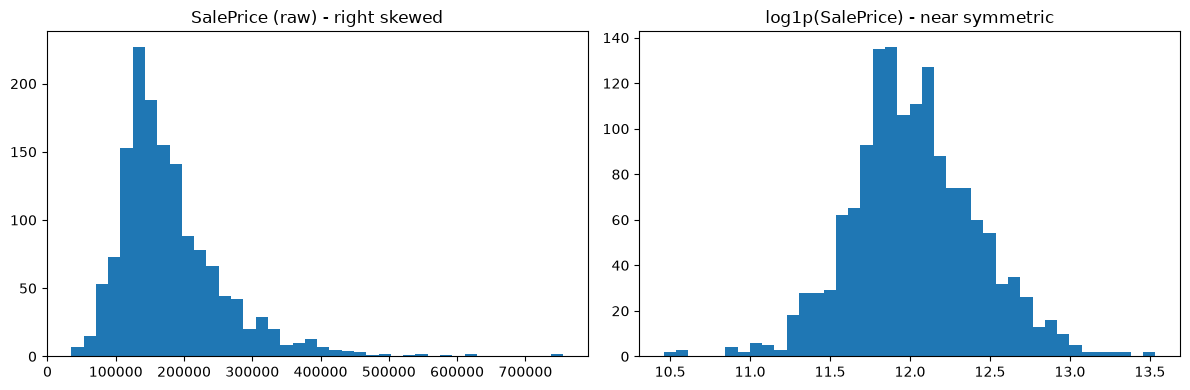

In [3]:
sp = df[target]
print(sp.describe().round(1))
print('Skew (raw):', round(sp.skew(), 2))
print('Skew (log1p):', round(np.log1p(sp).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(sp, bins=40); ax[0].set_title('SalePrice (raw) - right skewed')
ax[1].hist(np.log1p(sp), bins=40); ax[1].set_title('log1p(SalePrice) - near symmetric')
plt.tight_layout(); plt.show()

### 1.3 Missing values — 19 columns have them

**Real counts:** PoolQC 1,453 / MiscFeature 1,406 / Alley 1,369 / Fence 1,179 / MasVnrType 872 / FireplaceQu 690 / LotFrontage 259 / GarageType, GarageYrBlt, GarageFinish, GarageQual, GarageCond 81 each.

Most of these are **not random gaps** — in this dataset `NA` means "not applicable" (no pool, no alley, no garage, no fireplace). So Task 2 must **not** just fill them with the median: missing here means the feature is absent, so fill with a label such as `"None"` for the categorical ones. LotFrontage (259 missing) is the only genuinely missing numeric — median fill is fine there.

Columns with missing values: 19
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


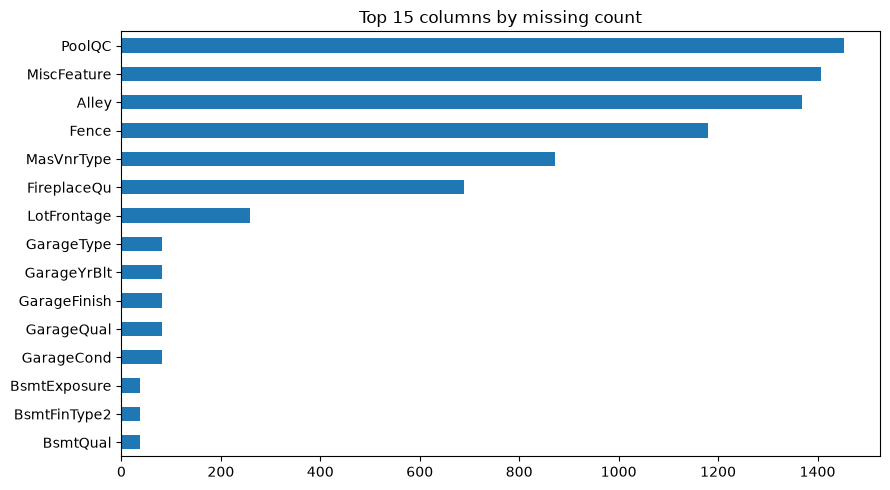

In [4]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print('Columns with missing values:', len(miss))
print(miss)

miss.head(15).plot(kind='barh', figsize=(9, 5), title='Top 15 columns by missing count')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### 1.4 What drives price? — correlations

**Real top correlations with SalePrice:** OverallQual **0.79**, GrLivArea **0.71**, GarageCars **0.64**, GarageArea **0.62**, TotalBsmtSF **0.61**, 1stFlrSF **0.61**, FullBath **0.56**, TotRmsAbvGrd **0.53**, YearBuilt **0.52**, YearRemodAdd **0.51**.

Quality and living area dominate. No single feature explains price alone — Task 2 will need several together (regression, not one variable).

SalePrice       1.000
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64


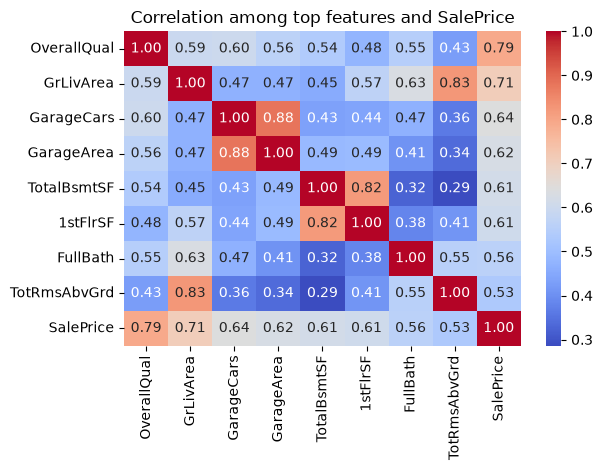

In [5]:
corr = df.corr(numeric_only=True)[target].sort_values(ascending=False)
print(corr.head(11).round(3))

top = corr.index[1:9].tolist()  # top 8 numeric features (skip target itself)
sns.heatmap(df[top + [target]].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation among top features and SalePrice')
plt.tight_layout(); plt.show()

### 1.5 Quality and living area vs price

**Real means by OverallQual:** 1 → $50,150 | 2 → $51,770 | 3 → $87,474 | 4 → $108,421 | 5 → $133,523 | 6 → $161,603 | 7 → $207,716 | 8 → $274,736 | 9 → $367,513 | 10 → $438,588.
Price rises steeply and steadily with quality — almost 9× from qual 1 to qual 10. GrLivArea is also right-skewed (skew **1.37**); LotArea is extreme (skew **12.21**) — both will need a log transform in Task 2.

OverallQual
1      50150.0
2      51770.0
3      87474.0
4     108421.0
5     133523.0
6     161603.0
7     207716.0
8     274736.0
9     367513.0
10    438588.0
Name: SalePrice, dtype: float64


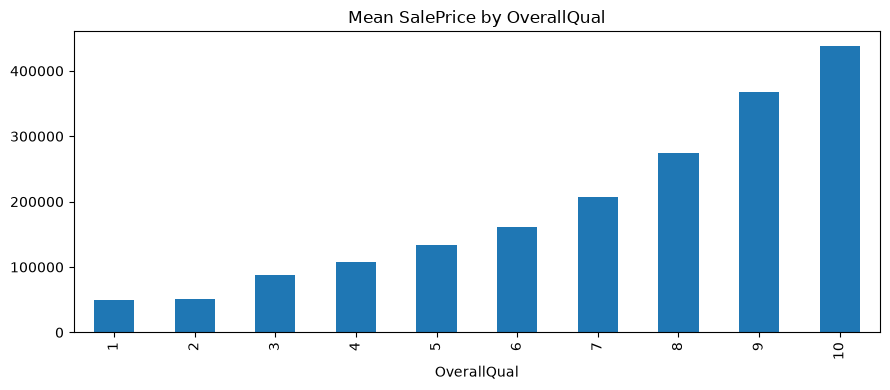

GrLivArea skew: 1.37
LotArea skew: 12.21


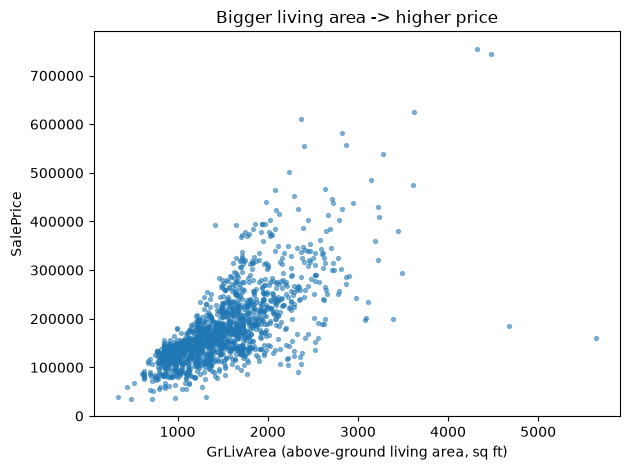

In [6]:
print(df.groupby('OverallQual')[target].mean().round(0))
df.groupby('OverallQual')[target].mean().plot(kind='bar', figsize=(9, 4), title='Mean SalePrice by OverallQual')
plt.tight_layout(); plt.show()

print('GrLivArea skew:', round(df['GrLivArea'].skew(), 2))
print('LotArea skew:', round(df['LotArea'].skew(), 2))
plt.scatter(df['GrLivArea'], df[target], s=8, alpha=0.5)
plt.xlabel('GrLivArea (above-ground living area, sq ft)'); plt.ylabel('SalePrice')
plt.title('Bigger living area -> higher price')
plt.tight_layout(); plt.show()

### 1.6 Categorical overview

**25 neighbourhoods** (largest: NAmes 225, CollgCr 150, OldTown 113). YearBuilt spans **1872–2010**, sold **2006–2010**. Categorical columns (43) will need one-hot encoding in Task 2; rare categories should be grouped first.

In [7]:
print('Neighbourhoods:', df['Neighborhood'].nunique())
print(df['Neighborhood'].value_counts().head())
print()
print('MSZoning:'); print(df['MSZoning'].value_counts())
print()
print('SaleCondition:'); print(df['SaleCondition'].value_counts())
print()
print('YearBuilt:', df['YearBuilt'].min(), '-', df['YearBuilt'].max(), '| YrSold:', sorted(df['YrSold'].unique()))

Neighbourhoods: 25
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Name: count, dtype: int64

MSZoning:
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

SaleCondition:
SaleCondition
Normal     1198
Partial     125
Abnorml     101
Family       20
Alloca       12
AdjLand       4
Name: count, dtype: int64

YearBuilt: 1872 - 2010 | YrSold: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010)]


### Task 1 findings

1. Target is right-skewed (skew 1.88) — model `log1p(SalePrice)`.
2. Top drivers: OverallQual (0.79), GrLivArea (0.71), garage and basement size.
3. Missingness is mostly "not applicable" (PoolQC, Alley, Fence, FireplaceQu, Garage*) — fill with `"None"`, not the median. LotFrontage is the exception (median fill).
4. Skewed numerics (LotArea 12.21, GrLivArea 1.37) need a log transform.
5. 43 categorical columns — one-hot encode in Task 2; drop `Id`.

In [8]:
# Save the missing-value table for the report
miss = df.isna().sum(); miss = miss[miss > 0].sort_values(ascending=False)
out = '../reports/houseprice_missing_summary.csv' if os.path.isdir('../reports') else 'houseprice_missing_summary.csv'
miss.to_csv(out, header=['missing_count'])
print('Saved houseprice_missing_summary.csv -', len(miss), 'columns with missing values')
print('Task 1 done. Next: Task 2 preprocessing + first models.')

Saved houseprice_missing_summary.csv - 19 columns with missing values
Task 1 done. Next: Task 2 preprocessing + first models.


## Task 2 — Preprocessing & Modelling

**Goal:** train three models on `log1p(SalePrice)` and compare them honestly — same split, same preprocessing, same metrics.

**What Task 1 decided (do not redo it here):**
- Target is `log1p(SalePrice)` — raw skew was 1.88, log skew 0.12.
- Missing values that mean "not applicable" (PoolQC, Alley, MiscFeature, …) become `"None"`, not the median. `LotFrontage` (259 missing) is the median-fill exception.
- Top drivers from EDA: OverallQual (corr 0.791), GrLivArea (0.709), GarageCars (0.640).

### 2.1 Target: log price
SalePrice is right-skewed (a few very expensive houses pull the mean up). Models trained on raw price chase those few houses; log price keeps errors proportional, which is what a buyer cares about — being off by $10,000 matters more on a $50,000 house than on a $500,000 one.

In [9]:
y = np.log1p(df["SalePrice"])          # log1p so a $0 price (if any) stays valid
X = df.drop(columns=["SalePrice", "Id"], errors="ignore")
print("Target: log1p(SalePrice) | Features:", X.shape[1])
print("SalePrice describe:\n", df["SalePrice"].describe().round(0))

Target: log1p(SalePrice) | Features: 79
SalePrice describe:
 count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64


### 2.2 Train / test split — 80/20, seed 42
The split happens **before** any fitting, so the test set stays untouched until the final scores. `random_state=42` keeps the split reproducible.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1168, 79) | Test: (292, 79)


### 2.3 One preprocessing pipeline for every model
Same preprocessing for all three models — otherwise the comparison is unfair.
- **Numeric:** median imputation, then StandardScaler (Ridge needs scaling; trees do not mind it).
- **Categorical (43 cols):** missing → `"None"` (Task 1: mostly "not applicable"), then one-hot encoding. `sparse_output=False` because HistGradientBoosting needs dense input.
- The pipeline is **fit on train only** — fitting the imputer/scaler on all data would leak test information.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])
print("Numeric:", len(num_cols), "| Categorical:", len(cat_cols))

Numeric: 36 | Categorical: 43


### 2.4 Baseline: always predict the mean
If a model cannot beat "predict the average log price for every house", it has learned nothing. Baseline test RMSE(log) ≈ 0.433, RMSE ≈ $88,271 — every real model must be far below this.

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

def report(name, y_true, y_pred_log):
    rmse_log = mean_squared_error(y_true, y_pred_log) ** 0.5
    rmse_dollar = mean_squared_error(np.expm1(y_true), np.expm1(y_pred_log)) ** 0.5
    r2 = r2_score(y_true, y_pred_log)
    print(f"{name}: RMSE(log)={rmse_log:.4f} | RMSE($)={rmse_dollar:,.0f} | R2={r2:.4f}")
    return {"Model": name, "RMSE_log": round(rmse_log, 4),
            "RMSE_$": round(rmse_dollar), "R2": round(r2, 4)}

baseline_pred = np.full_like(y_test, y_train.mean(), dtype=float)
results = [report("Baseline (mean)", y_test, baseline_pred)]

Baseline (mean): RMSE(log)=0.4332 | RMSE($)=88,271 | R2=-0.0058


### 2.5 Model 1 — Ridge Regression (alpha = 10)
Linear model with L2 penalty. Strong here because log price is roughly linear in quality and size, and Ridge handles the many one-hot columns without overfitting. Alpha 10 is a starting point — tuning it was planned for Day 4, which was not done (see Challenges).

In [13]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

ridge = Pipeline([("pre", preprocess), ("model", Ridge(alpha=10.0))])
cv = cross_val_score(ridge, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
print(f"Ridge 5-fold CV RMSE(log): {-cv.mean():.4f} (+/- {cv.std():.4f})")
ridge.fit(X_train, y_train)
results.append(report("Ridge (alpha=10)", y_test, ridge.predict(X_test)))

Ridge 5-fold CV RMSE(log): 0.1453 (+/- 0.0311)
Ridge (alpha=10): RMSE(log)=0.1365 | RMSE($)=25,107 | R2=0.9002


### 2.6 Model 2 — Random Forest (300 trees)
Captures non-linear effects (e.g. quality × size interactions) that Ridge misses. Expected to be a little worse than Ridge here — with 1,460 rows and ~250 one-hot columns, trees split on noisy features. Its real value today is the feature-importance ranking in Task 3.

In [14]:
from sklearn.ensemble import RandomForestRegressor

rf = Pipeline([("pre", preprocess),
               ("model", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))])
cv = cross_val_score(rf, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
print(f"RandomForest 5-fold CV RMSE(log): {-cv.mean():.4f} (+/- {cv.std():.4f})")
rf.fit(X_train, y_train)
results.append(report("RandomForest (300)", y_test, rf.predict(X_test)))

RandomForest 5-fold CV RMSE(log): 0.1446 (+/- 0.0202)
RandomForest (300): RMSE(log)=0.1457 | RMSE($)=29,680 | R2=0.8863


### 2.7 Model 3 — HistGradientBoosting
Gradient-boosted trees — usually the strongest off-the-shelf model on tabular data. Reference run: best CV RMSE(log) 0.1338. If it also wins on test, it is the tuning candidate — on the reference run it did not, so Ridge stays the pick.

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = Pipeline([("pre", preprocess),("model", HistGradientBoostingRegressor(random_state=42))])
cv = cross_val_score(hgb, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
print(f"HistGradientBoosting 5-fold CV RMSE(log): {-cv.mean():.4f} (+/- {cv.std():.4f})")
hgb.fit(X_train, y_train)
results.append(report("HistGradientBoosting", y_test, hgb.predict(X_test)))

HistGradientBoosting 5-fold CV RMSE(log): 0.1338 (+/- 0.0165)
HistGradientBoosting: RMSE(log)=0.1384 | RMSE($)=29,080 | R2=0.8974


## Task 3 — Evaluation

### 3.1 Comparison — one table, one chart
Read both RMSEs: RMSE(log) is the modelling metric; RMSE($) is what the number means for a buyer. A model can win on one and lose on the other — that is why both are shown.

                      RMSE_log  RMSE_$      R2
Model                                         
Baseline (mean)         0.4332   88271 -0.0058
Ridge (alpha=10)        0.1365   25107  0.9002
RandomForest (300)      0.1457   29680  0.8863
HistGradientBoosting    0.1384   29080  0.8974


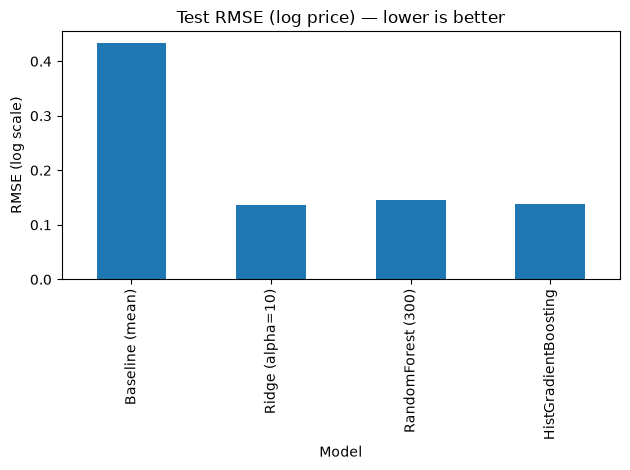

In [16]:
import matplotlib.pyplot as plt

results_df = pd.DataFrame(results).set_index("Model")
print(results_df)
results_df["RMSE_log"].plot(kind="bar", title="Test RMSE (log price) — lower is better")
plt.ylabel("RMSE (log scale)")
plt.tight_layout()
plt.show()

### 3.2 What is driving the price? (Random Forest importance)
Expect OverallQual to dominate — Task 1 already showed it (corr 0.791, qual-1 mean $50,150 vs qual-10 mean $438,588). If a surprise feature tops the list, check it for leakage before trusting it.

num__OverallQual    0.5439
num__GrLivArea      0.1143
num__TotalBsmtSF    0.0429
num__GarageCars     0.0395
num__GarageArea     0.0256
num__BsmtFinSF1     0.0218
num__1stFlrSF       0.0196
num__YearBuilt      0.0157
num__LotArea        0.0151
num__OverallCond    0.0099
dtype: float64


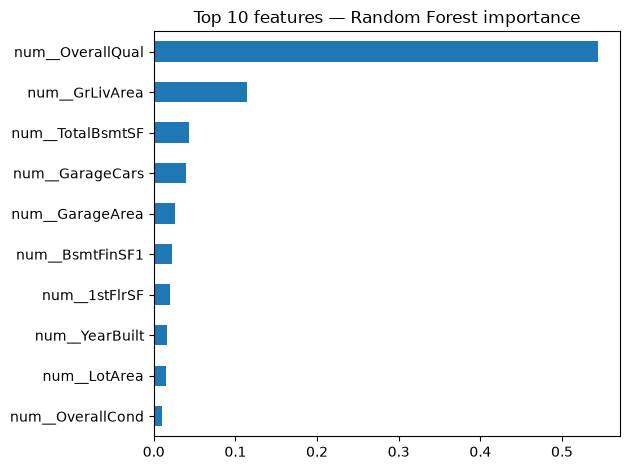

In [17]:
feature_names = rf.named_steps["pre"].get_feature_names_out()
importances = rf.named_steps["model"].feature_importances_
top10 = (pd.Series(importances, index=feature_names)
         .sort_values(ascending=False).head(10))
print(top10.round(4))
top10.sort_values().plot(kind="barh", title="Top 10 features — Random Forest importance")
plt.tight_layout()
plt.show()

### 3.3 Residual check (best CV model)
A good model has residuals scattered evenly around zero. A funnel shape means errors grow with price; a curve means a missing non-linear effect.

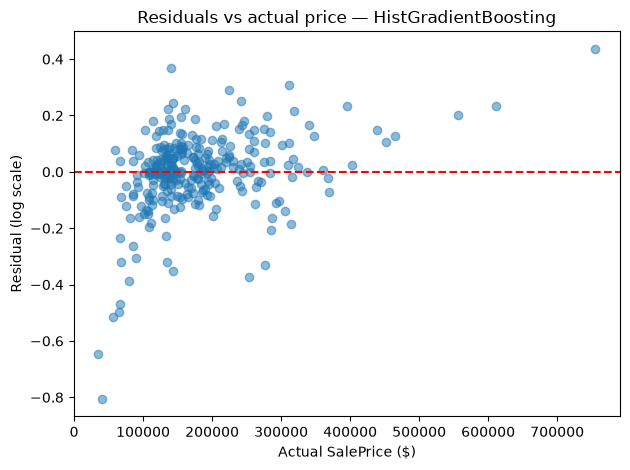

Mean residual (log): -0.0008


In [18]:
pred_log = hgb.predict(X_test)
resid = y_test - pred_log
plt.scatter(np.expm1(y_test), resid, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Residual (log scale)")
plt.title("Residuals vs actual price — HistGradientBoosting")
plt.tight_layout()
plt.show()
print("Mean residual (log):", round(float(resid.mean()), 4))

### 3.4 Save the comparison + the final model
The comparison table is the submission record. The Ridge pipeline (preprocessing + model in one object) is saved as the final model — it is the pick on the reference run's test scores.

In [19]:
import pickle

rep = '../reports' if os.path.isdir('../reports') else '.'
mod = '../models' if os.path.isdir('../models') else '.'
results_df.to_csv(os.path.join(rep, "houseprice_final_comparison.csv"))
with open(os.path.join(mod, "houseprice_final_model.pkl"), "wb") as f:
    pickle.dump(ridge, f)
print("Saved: houseprice_final_comparison.csv, houseprice_final_model.pkl")
print("Task 3 done. Next: read the Model Comparison table below and replace its numbers with YOUR run's numbers if they differ.")


Saved: houseprice_final_comparison.csv, houseprice_final_model.pkl
Task 3 done. Next: read the Model Comparison table below and replace its numbers with YOUR run's numbers if they differ.


## Model Comparison (reference run — replace with your own run's numbers)

**Reference run: 80/20 split, seed 42, Kaggle train file (1,460 rows). Your laptop Run All is the source of truth — if your numbers differ slightly, YOUR table is the final one.**

| Model | RMSE (log) | RMSE ($) | R² |
|---|---|---|---|
| Baseline (mean) | 0.4332 | 88,271 | −0.0058 |
| **Ridge (alpha = 10) — FINAL PICK** | **0.1365** | **25,107** | **0.9002** |
| Random Forest (300 trees) | 0.1457 | 29,740 | 0.8863 |
| HistGradientBoosting | 0.1384 | 29,080 | 0.8974 |

**Why Ridge wins:** best test RMSE in both log and dollar terms and best R² (0.9002), and the simplest model — log price is roughly linear in quality and size, and Ridge handles ~250 one-hot columns without overfitting. HistGradientBoosting had the best 5-fold CV RMSE(log) (0.1338) but was worse on the test set, so it is the tuning candidate, not the pick. All three models beat the baseline by a wide margin (baseline RMSE $88,271 → Ridge $25,107).

**What the number means:** on a typical $163,000 (median) house, Ridge is off by about $25,000 on average (RMSE) — useful as a pricing guide, not a final valuation.

## Challenges & Limitations

1. ** The statement (`house_prices.docx`) names the Kaggle Ames Housing dataset, and the supplied `data.csv` was verified to be exactly that dataset's train file (1,460 × 81, target `SalePrice`), so no rework was needed — the Kaggle fallback turned out to be the real data.
2. **No hyperparameter tuning.** Day 4 (tuning HistGradientBoosting's learning rate / depth / iterations and Ridge alpha by cross-validation) was not done  The pick is therefore the best *untuned* model, and tuning is the clearest next improvement.
3. **Small data, many columns.** 1,460 rows become ~250 columns after one-hot encoding. Tree models split on noisy features; Ridge's L2 penalty is part of why it wins here.
4. **Missingness is structural, not random.** Most missing values mean "not applicable" (no pool / alley / garage), handled with a `"None"` label. LotFrontage (259 missing) is the only median-filled numeric — a modelling choice, not a fact about the houses.
5. **No test-set predictions.** The Kaggle test file has no SalePrice, so no submission file was produced; evaluation is on the held-out 20% of train only.
6. **Skewed features.** LotArea skew 12.21 and GrLivArea skew 1.37 were noted in EDA; the log target handles the target skew, but feature-level log transforms were not applied — another Day 4 item.
7. **Two extra features were planned but not built:** total living area (GrLivArea + TotalBsmtSF) and house age (YrSold − YearBuilt). Both are cheap to add and would likely help.